# Trend, seasonality, cycles and noise in psychology's monthly output, 2001–2024

This notebook breaks a monthly series of publication counts into four parts with Prophet: a long-run **trend**, a **seasonal** pattern that repeats every year, slower **cycles** that last a year or more, and **noise**. The series is the number of psychology journal articles published each month from 2001 to 2024, for the whole field and for its research topics.

The research project asks whether the semantic breadth of a field changes as its output grows. Its outcome, knowledge extent (KE), is measured on 1,000-paper samples, so it exists only per year, and a monthly KE series would rest on too few papers. Publication counts, however, are the project's growth variable, and they can be counted month by month. This notebook therefore studies the growth side of the question. How smooth is psychology's growth? Which changes in its growth rate are real? And how much of a topic's change from one period to the next is noise?

The steps follow the course's Prophet example (a baseline fit, its components, a correction, trend changepoints and flexibility, conditional seasonality), with one addition the data need: OpenAlex dates many papers 1 January, which has to be dealt with before any seasonality can be read.

All model settings were written into the project's decision log on 2026-11-23, before the first fit.

## Literature Review

The growth of science has long been described with simple curves. Price (1963) described it as exponential, with output doubling roughly every 10 to 15 years. Bornmann, Haunschild and Mutz (2021) revisited the question with modern publication databases and fitted *piecewise* growth curves, in which growth proceeds in segments with different rates; they estimate an overall growth rate of 4.10% a year. A segmented growth curve is what Prophet's trend is: a line on the log scale whose slope, the growth rate, changes at a few changepoints. Fitting it to monthly counts asks where psychology's growth rate changed, and by how much, while keeping the seasonal pattern out of the estimate.

Prophet (Taylor & Letham, 2018) writes a series as y(t) = g(t) + s(t) + h(t) + ε<sub>t</sub>: a trend g, seasonality s, holiday effects h, and an error term. The trend is piecewise linear. By default it has 25 potential changepoints spread over the first 80% of the series, and a Laplace prior on the size of each change, so most potential changepoints receive almost no change and only a few matter. The scale of that prior, `changepoint_prior_scale`, sets how flexible the trend is. Seasonality is a Fourier series, a sum of sine and cosine waves with a one-year period. I fit Prophet to the logarithm of the counts, so each component is a relative effect: a seasonal value of 0.10 means about 10% above the trend.

Prophet has no cycle term. In the decomposition tradition summarised by Hyndman and Athanasopoulos (2021, ch. 2–3), a series has a trend-cycle, a seasonal component, and a remainder, and a *cycle* is a rise and fall that does not have a fixed period (unlike seasonality), usually lasting two years or more. For monthly data, the classical way to estimate the trend-cycle is a centred 2×12 moving average, which averages over exactly one year and so removes the seasonal pattern. I use the same tool on what Prophet leaves unexplained: the 2×12 moving average of Prophet's residual is the cycle, and what remains is noise.

**References**

- Bornmann, L., Haunschild, R., & Mutz, R. (2021). Growth rates of modern science: A latent piecewise growth curve approach to model publication numbers from established and new literature databases. *Humanities and Social Sciences Communications*, 8, 224. https://doi.org/10.1057/s41599-021-00903-w
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/
- Price, D. J. de S. (1963). *Little science, big science*. Columbia University Press.
- Taylor, S. J., & Letham, B. (2018). Forecasting at scale. *The American Statistician*, 72(1), 37–45. https://doi.org/10.1080/00031305.2017.1380080

In [1]:
import logging
from pathlib import Path

logging.getLogger("prophet.plot").disabled = True   # plotly is not installed; all plots here are static
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from prophet import Prophet
import statsmodels.formula.api as smf
from statsmodels.tsa.stattools import acf

logging.getLogger("cmdstanpy").disabled = True      # otherwise Stan prints two lines per fit

MONTHLY = Path("data/topic_sample/psychology_field32/monthly")                # src/openalex_monthly_counts.py
TOPIC_COUNTS = Path("data/topic_sample/psychology_field32/topic_counts.csv")  # src/openalex_topic_sample.py
TABLES, FIGURES = Path("outputs/tables"), Path("outputs/figures")
for folder in (TABLES, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# chart style (as in the other notebooks): thin lines, recessive grid, text in ink colours
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

def style_axes(ax):
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED)

def save(fig, name):
    fig.savefig(FIGURES / f"week7_{name}.png", dpi=150, bbox_inches="tight")

## 1. Data

The counts come from OpenAlex, pulled on 2026-11-23 with `src/openalex_monthly_counts.py`. A paper is a psychology journal article if its primary topic is in OpenAlex field 32 (Psychology), it is an English-language article in a journal, it is not paratext, and it is in OpenAlex's core corpus; these are the project's rules for N<sub>t</sub>, with or without an abstract. For every year there is one count per topic for each calendar month, one for the whole year, and one for papers dated exactly 1 January. The twelve months add up to the annual count in every year.

**The 1 January problem.** OpenAlex records a publication date for every paper. When the source gives only a year, the date becomes 1 January of that year; when it gives a month but no day, the date becomes the first of that month. So January holds three kinds of papers: papers published in January, papers from January issues (dated 1 January), and papers whose month is unknown (also dated 1 January). The last group is large in the early years.

One note on the definition: OpenAlex reassigned some topics between fields on 2026-11-23, so this field-32 count is smaller than the one used for the project's KE pool (24,810 articles in 2001 here, 29,631 in the earlier count). The project will move everything to the new definition later.

In [2]:
monthly = pd.read_csv(MONTHLY / "monthly_counts.csv")   # topic_id, topic_name, year, month, journal_articles
annual = pd.read_csv(MONTHLY / "annual_counts.csv")     # ... journal_articles, months_sum, jan1_articles
print(f"{monthly['topic_id'].nunique()} topics, {monthly['year'].min()}–{monthly['year'].max()}, "
      f"{annual['journal_articles'].sum():,} journal articles")

def add_dates(frame):
    frame = frame.copy()
    frame["ds"] = pd.to_datetime(frame[["year", "month"]].assign(day=1))   # Prophet's date column
    return frame

def spread_jan1(frame):
    """Take the papers dated 1 January out of January and spread them evenly over their year."""
    frame = frame.copy()
    frame["spread"] = (frame["journal_articles"] - np.where(frame["month"] == 1, frame["jan1_articles"], 0)
                       + frame["jan1_articles"] / 12)
    return frame

field = (monthly.groupby(["year", "month"], as_index=False)["journal_articles"].sum()
         .merge(annual.groupby("year", as_index=False)["jan1_articles"].sum(), on="year"))
field = spread_jan1(add_dates(field)).sort_values("ds").reset_index(drop=True)

yearly = field.groupby("year").agg(articles=("journal_articles", "sum"), spread=("spread", "sum"),
                                   jan1=("jan1_articles", "first"))
assert np.allclose(yearly["spread"], yearly["articles"])   # spreading keeps every year's total
yearly["january_share"] = field.loc[field["month"] == 1].set_index("year")["journal_articles"] / yearly["articles"]
yearly["jan1_share"] = yearly["jan1"] / yearly["articles"]

shown = yearly.loc[[2001, 2006, 2011, 2016, 2021, 2024]]
pd.DataFrame({"articles": shown["articles"].map("{:,}".format),
              "dated in January": shown["january_share"].map("{:.1%}".format),
              "dated 1 January": shown["jan1_share"].map("{:.1%}".format)})

126 topics, 2001–2024, 1,559,033 journal articles


,articles,dated in January,dated 1 January
year,,,
2001,"24,810",26.6%,26.0%
2006,"38,091",31.8%,29.7%
2011,"54,029",29.5%,26.2%
2016,"72,993",19.5%,14.8%
2021,"112,000",16.5%,10.9%
2024,"128,656",14.5%,8.5%


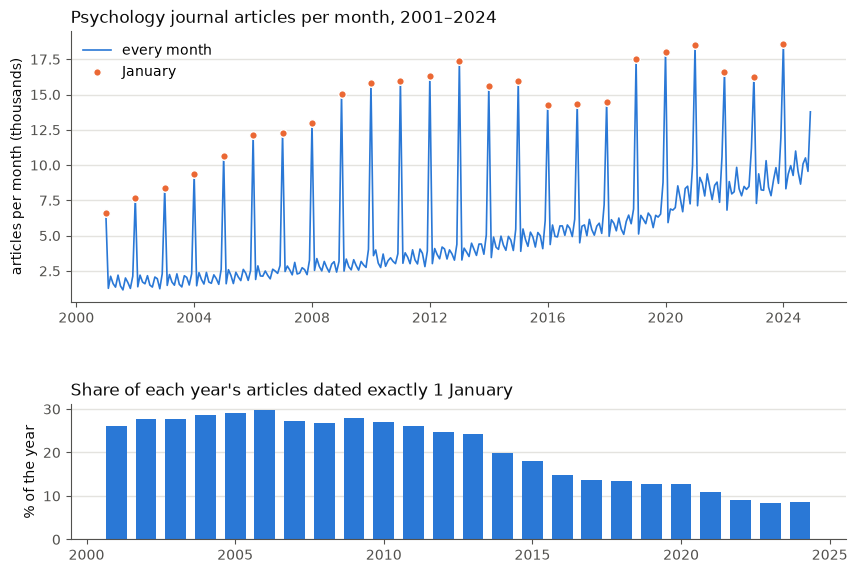

In [3]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6.6), gridspec_kw={"height_ratios": [2, 1], "hspace": 0.5})
top.plot(field["ds"], field["journal_articles"] / 1000, color=BLUE, lw=1.2, label="every month")
january = field[field["month"] == 1]
top.scatter(january["ds"], january["journal_articles"] / 1000, s=30, color=ORANGE, edgecolor="white",
            linewidth=1, zorder=3, label="January")
top.set_ylabel("articles per month (thousands)", color=INK)
top.set_title("Psychology journal articles per month, 2001–2024", loc="left", color=INK)
top.legend(frameon=False, loc="upper left")
bottom.bar(yearly.index, 100 * yearly["jan1_share"], width=0.7, color=BLUE)
bottom.set_ylabel("% of the year", color=INK)
bottom.set_title("Share of each year's articles dated exactly 1 January", loc="left", color=INK)
for ax in (top, bottom):
    style_axes(ax)
save(fig, "field_monthly")
plt.show()

Output grew about fivefold, from 24,810 articles in 2001 to 128,656 in 2024. Every January stands far above the months around it. In 2001, 26.6% of the year's articles are dated January and 26.0% are dated exactly 1 January, so almost all of January's excess sits on a single day. That share falls to 8.5% by 2024 as publishers report fuller dates, but it never disappears. This spike comes from how the dates were recorded, not from when papers were published.

## 2. The baseline: Prophet on the raw counts

The first model is Prophet on the logarithm of the raw monthly counts. Settings follow the decision log: a linear trend with the default `changepoint_prior_scale` of 0.05, and yearly seasonality with Fourier order 5. Order 5 means five sine–cosine pairs, enough for a pattern that changes from month to month (monthly data allow at most order 6). Weekly and daily seasonality are off because the data are monthly. The helper below fits one model and returns its fitted components; `y` may contain missing months, which Prophet simply leaves out of the fit.

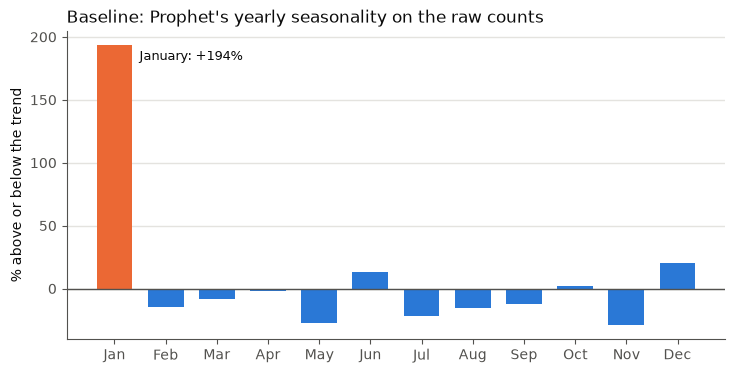

In [4]:
def fit_prophet(frame, y, changepoint_prior_scale=0.05, conditional=False):
    """Fit Prophet to monthly log counts y (NaN = not observed); return the model and its fitted parts."""
    data = pd.DataFrame({"ds": frame["ds"].to_numpy(), "y": np.asarray(y, dtype=float)})
    data["first_half"] = data["ds"].dt.year <= 2012        # used only by the conditional model (Section 5)
    data["second_half"] = ~data["first_half"]
    model = Prophet(yearly_seasonality=False if conditional else 5, weekly_seasonality=False,
                    daily_seasonality=False, changepoint_prior_scale=changepoint_prior_scale)
    if conditional:
        model.add_seasonality("yearly_2001_2012", period=365.25, fourier_order=5, condition_name="first_half")
        model.add_seasonality("yearly_2013_2024", period=365.25, fourier_order=5, condition_name="second_half")
    model.fit(data)
    fitted = model.predict(data.drop(columns="y"))
    fitted["y"] = data["y"].to_numpy()
    fitted["seasonal"] = fitted["yhat"] - fitted["trend"]   # the yearly term(s); there are no holidays
    return model, fitted

def seasonal_by_month(fitted, rows=None):
    """The seasonal effect at each month start, in % above or below the trend."""
    fitted = fitted if rows is None else fitted[rows]
    return 100 * (np.exp(fitted.groupby(fitted["ds"].dt.month)["seasonal"].mean()) - 1)

baseline_model, baseline = fit_prophet(field, np.log(field["journal_articles"]))
baseline_effect = seasonal_by_month(baseline)

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(MONTHS, baseline_effect, width=0.7, color=[ORANGE if m == 1 else BLUE for m in baseline_effect.index])
ax.axhline(0, color=MUTED, lw=1)
ax.annotate(f"January: +{baseline_effect.loc[1]:.0f}%", (0, baseline_effect.loc[1]), xytext=(18, -4),
            textcoords="offset points", va="top", color=INK, fontsize=9)
ax.set_ylabel("% above or below the trend", color=INK)
ax.set_title("Baseline: Prophet's yearly seasonality on the raw counts", loc="left", color=INK)
style_axes(ax)
save(fig, "baseline_seasonality")
plt.show()

**Diagnosis.** The baseline reads the recording artefact as seasonality. It puts January at nearly three times the trend (+194%) and, to keep the yearly average at zero, pushes the other eleven months below it. The 1 January spike also shrinks over time, from 26% of the year to 8.5%, and a seasonal term that repeats unchanged every year cannot follow that decline, so part of the decline ends up in the residual. Both problems come from the January papers whose month is unknown.

## 3. Fixing the January problem

The fix has two parts.

1. **Spread the 1 January papers over their year.** They are removed from January and one twelfth is added to every month. Every year keeps its total, so the trend still counts every paper.
2. **Treat January as missing.** January issues are also dated 1 January, so spreading moves real January papers out of January too, and January becomes the smallest month of every year (2.8% of 2001's articles). January's true count cannot be recovered from the dates, so the model is fitted on the other eleven months, and Prophet's seasonal curve fills in January from its neighbours.

The course example solved a similar problem (a known disturbance distorting the trend and seasonality) with holiday terms. A holiday term would not work here because the size of the January artefact changes every year.

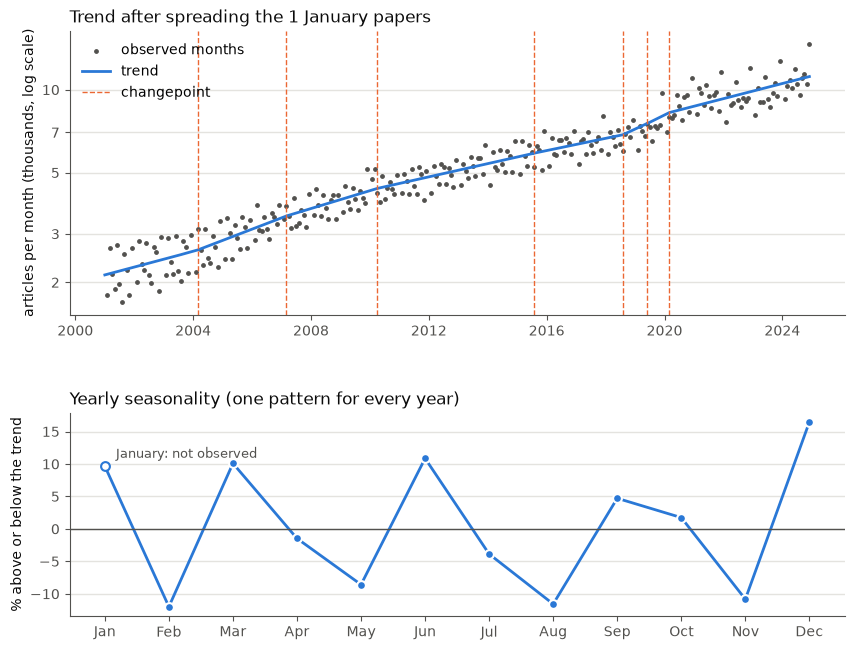

,changepoint,growth change (points per year)
0,2004-03,2.6
1,2007-03,-2.0
2,2010-04,-1.9
3,2015-08,-0.4
4,2018-08,6.2
5,2019-06,0.9
6,2020-03,-5.9


In [5]:
y_fixed = np.log(field["spread"]).where(field["month"] != 1)   # January is not observed
fixed_model, fixed = fit_prophet(field, y_fixed)

def changepoints(model, threshold=0.01):
    """Changepoints whose rate change passes Prophet's plotting threshold, with the change in annual growth."""
    delta = model.params["delta"].mean(axis=0)
    years = (model.history["ds"].max() - model.history["ds"].min()).days / 365.25   # Prophet scales time to 0-1
    per_year = model.y_scale / years                                                # scaled slope -> log points per year
    table = pd.DataFrame({"changepoint": model.changepoints.dt.strftime("%Y-%m").to_numpy(),
                          "growth change (points per year)": np.round(100 * delta * per_year, 1)})
    return table[np.abs(delta) >= threshold].reset_index(drop=True)

fixed_changes = changepoints(fixed_model)
fixed_effect = seasonal_by_month(fixed)

fig, (left, right) = plt.subplots(2, 1, figsize=(10, 7.6), gridspec_kw={"height_ratios": [1.4, 1], "hspace": 0.4})
left.scatter(field["ds"], field["spread"].where(field["month"] != 1) / 1000, s=6, color=MUTED, label="observed months")
left.plot(fixed["ds"], np.exp(fixed["trend"]) / 1000, color=BLUE, lw=2, label="trend")
for date in pd.to_datetime(fixed_changes["changepoint"]):
    left.axvline(date, color=ORANGE, lw=1, ls="--")
left.plot([], [], color=ORANGE, lw=1, ls="--", label="changepoint")
left.set_yscale("log")
left.minorticks_off()
left.set_yticks([2, 3, 5, 7, 10])
left.set_yticklabels(["2", "3", "5", "7", "10"])
left.set_ylabel("articles per month (thousands, log scale)", color=INK)
left.set_title("Trend after spreading the 1 January papers", loc="left", color=INK)
left.legend(frameon=False, loc="upper left")
right.plot(range(12), fixed_effect, color=BLUE, lw=2)
right.scatter(range(1, 12), fixed_effect.loc[2:], s=40, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
right.scatter([0], [fixed_effect.loc[1]], s=40, facecolor="white", edgecolor=BLUE, linewidth=1.5, zorder=3)
right.annotate("January: not observed", (0, fixed_effect.loc[1]), xytext=(8, 6), textcoords="offset points",
               color=MUTED, fontsize=9)
right.axhline(0, color=MUTED, lw=1)
right.set_xticks(range(12), MONTHS)
right.set_ylabel("% above or below the trend", color=INK)
right.set_title("Yearly seasonality (one pattern for every year)", loc="left", color=INK)
for ax in (left, right):
    style_axes(ax)
save(fig, "fixed_components")
plt.show()
fixed_changes

With the artefact removed, a real seasonal pattern appears: **quarterly peaks** in March, June, September and December, each followed by a low month. This is what journals with four issues a year would produce. December is the strongest month (+16% over the trend), and February, August and November are the weakest (11–12% below it).

The trend grows throughout, and Prophet keeps seven changepoints (table above; the change is in percentage points of annual growth). Growth speeds up in 2004 (+2.6 points), slows in 2007 and 2010 (about −2 points each), and slows slightly in 2015. In August 2018 it speeds up by 6.2 points, and in March 2020 it slows by 5.9: output surged in 2019–2020, then returned to its earlier pace. Prophet places changepoints only in the first 80% of the series, so after mid-2020 the trend is a straight line by construction.

## 4. Tuning trend flexibility

The default `changepoint_prior_scale` of 0.05 lets few changepoints matter. Raising it to 0.5 makes the trend ten times more flexible. If the two trends look the same, the default is not hiding real changes; if the flexible one follows every bump, it is overfitting.

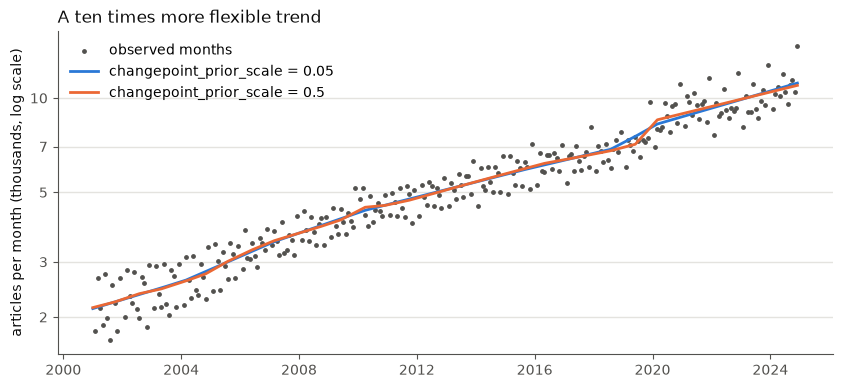

,changepoints kept,residual SD (log points)
0.05 (default),7,0.0547
0.5,17,0.0526


In [6]:
flexible_model, flexible = fit_prophet(field, y_fixed, changepoint_prior_scale=0.5)

def residual_sd(fitted):
    return (fitted["y"] - fitted["yhat"]).std()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.scatter(field["ds"], field["spread"].where(field["month"] != 1) / 1000, s=6, color=MUTED, label="observed months")
ax.plot(fixed["ds"], np.exp(fixed["trend"]) / 1000, color=BLUE, lw=2, label="changepoint_prior_scale = 0.05")
ax.plot(flexible["ds"], np.exp(flexible["trend"]) / 1000, color=ORANGE, lw=2, label="changepoint_prior_scale = 0.5")
ax.set_yscale("log")
ax.minorticks_off()
ax.set_yticks([2, 3, 5, 7, 10])
ax.set_yticklabels(["2", "3", "5", "7", "10"])
ax.set_ylabel("articles per month (thousands, log scale)", color=INK)
ax.set_title("A ten times more flexible trend", loc="left", color=INK)
ax.legend(frameon=False, loc="upper left")
style_axes(ax)
save(fig, "changepoint_flexibility")
plt.show()

pd.DataFrame({"changepoints kept": [len(changepoints(m)) for m in (fixed_model, flexible_model)],
              "residual SD (log points)": [round(residual_sd(f), 4) for f in (fixed, flexible)]},
             index=["0.05 (default)", "0.5"])

The flexible trend keeps 17 changepoints instead of 7, but it follows the same path, with a sharper step in 2020 as its main difference; the residual standard deviation falls only from 0.055 to 0.053. The extra flexibility mostly traces small wiggles rather than finding new turning points, so the default is kept. The main features, faster growth in the 2000s, slower growth in the 2010s, and the 2019–2020 surge, appear at both settings.

## 5. Did the seasonal pattern change?

Quarterly issues matter less once articles appear online as soon as they are ready, so the seasonal pattern may have weakened. As in the course example, conditional seasonality tests this: the model gets one yearly seasonality for 2001–2012 and a separate one for 2013–2024, splitting the period at its midpoint (fixed in the decision log before fitting).

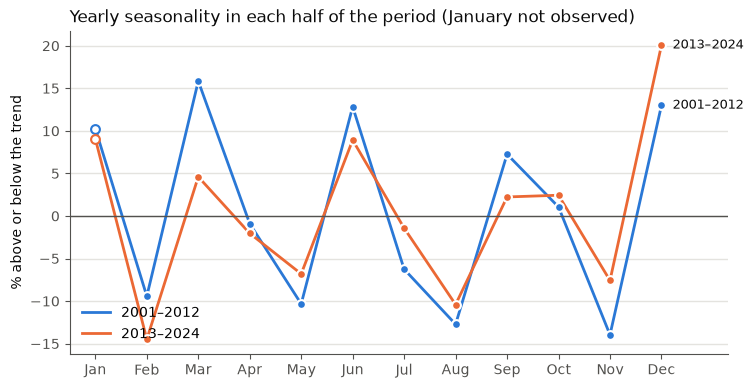

,residual SD (log points)
one seasonality,0.0547
one per half,0.0474


In [7]:
final_model, final = fit_prophet(field, y_fixed, conditional=True)
first_half = final["ds"].dt.year <= 2012
early, late = seasonal_by_month(final, first_half), seasonal_by_month(final, ~first_half)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for effect, color, label in ((early, BLUE, "2001–2012"), (late, ORANGE, "2013–2024")):
    ax.plot(range(12), effect, color=color, lw=2, label=label)
    ax.scatter(range(1, 12), effect.loc[2:], s=40, color=color, edgecolor="white", linewidth=1.5, zorder=3)
    ax.scatter([0], [effect.loc[1]], s=40, facecolor="white", edgecolor=color, linewidth=1.5, zorder=3)
    ax.annotate(label, (11, effect.loc[12]), xytext=(8, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(range(12), MONTHS)
ax.set_xlim(-0.5, 12.3)
ax.set_ylabel("% above or below the trend", color=INK)
ax.set_title("Yearly seasonality in each half of the period (January not observed)", loc="left", color=INK)
ax.legend(frameon=False, loc="lower left")
style_axes(ax)
save(fig, "conditional_seasonality")
plt.show()

pd.DataFrame({"residual SD (log points)": [round(residual_sd(f), 4) for f in (fixed, final)]},
             index=["one seasonality", "one per half"])

The pattern did change. In 2001–2012 the quarterly peaks are pronounced (March +16%, June +13%, September +7%, December +13%). In 2013–2024 March and September are only 2–5% above the trend, while December (+20%) is by far the largest peak, with June (+9%) second. Fitting a separate seasonality for each half lowers the residual standard deviation from 0.055 to 0.047, the largest improvement of any step after the January fix. This conditional model is the final model used in the rest of the notebook.

## 6. Cycles and noise

Prophet's residual, the log count minus trend and seasonality, still contains slow swings that the piecewise-linear trend cannot follow. The **cycle** is the centred 2×12 moving average of that residual: an average over 13 months with half weight on the two end months, so every calendar month counts equally. Where a window contains a January, it averages the 11 observed months. **Noise** is the residual minus the cycle. By construction, trend + seasonality + cycle + noise equals the series in every observed month (the first and last six months have no cycle).

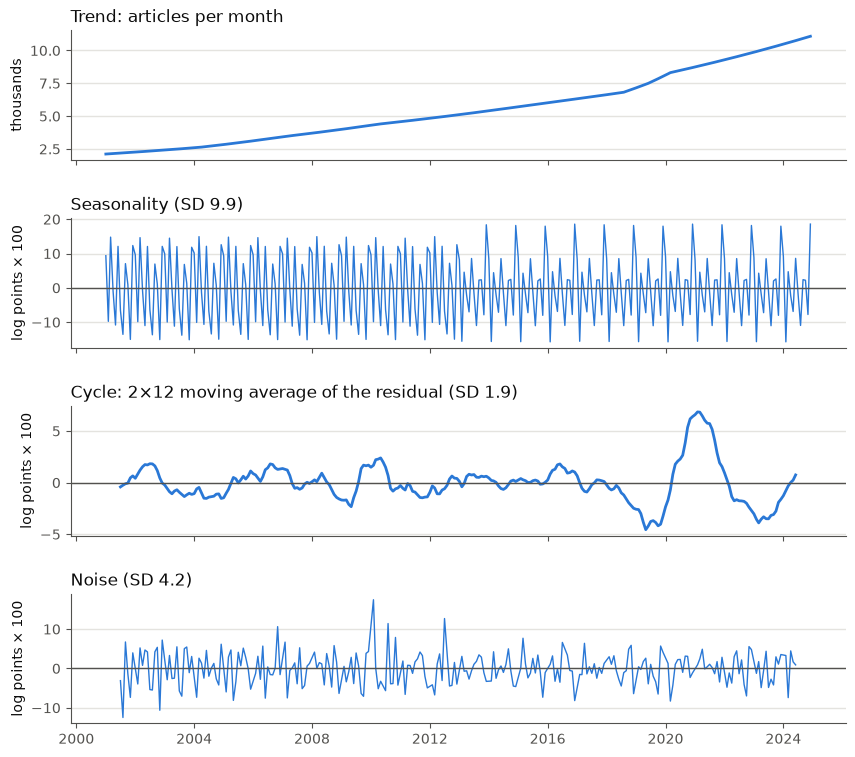

In [8]:
def cycle_and_noise(fitted):
    """Cycle: centred 2x12 moving average of the residual (11 observed months per window); noise: the rest."""
    residual = fitted["y"] - fitted["yhat"]
    cycle = residual.rolling(12, min_periods=11).mean().rolling(2).mean().shift(-6)
    return cycle, residual - cycle

final["cycle"], final["noise"] = cycle_and_noise(final)
parts = final[["trend", "seasonal", "cycle", "noise"]].sum(axis=1, min_count=4)
assert np.allclose(parts.dropna(), final.loc[parts.notna(), "y"])   # the four parts add up to the series
final[["ds", "y", "trend", "seasonal", "cycle", "noise"]].to_csv(TABLES / "week7_field_components.csv", index=False)

observed = final["y"].notna()
sd = {name: 100 * final.loc[observed, name].std() for name in ("seasonal", "cycle", "noise")}
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True, gridspec_kw={"hspace": 0.45})
axes[0].plot(final["ds"], np.exp(final["trend"]) / 1000, color=BLUE, lw=2)
axes[0].set_ylabel("thousands", color=INK)
axes[0].set_title("Trend: articles per month", loc="left", color=INK)
axes[1].plot(final["ds"], 100 * final["seasonal"], color=BLUE, lw=1)
axes[1].set_title(f"Seasonality (SD {sd['seasonal']:.1f})", loc="left", color=INK)
axes[2].plot(final["ds"], 100 * final["cycle"], color=BLUE, lw=2)
axes[2].set_title(f"Cycle: 2×12 moving average of the residual (SD {sd['cycle']:.1f})", loc="left", color=INK)
axes[3].plot(final.loc[observed, "ds"], 100 * final.loc[observed, "noise"], color=BLUE, lw=1)
axes[3].set_title(f"Noise (SD {sd['noise']:.1f})", loc="left", color=INK)
for ax in axes[1:]:
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_ylabel("log points × 100", color=INK)
for ax in axes:
    style_axes(ax)
save(fig, "decomposition")
plt.show()

The four parts, on the log scale (log points × 100 are close to percentages):

- **Trend.** From about 2,200 articles a month in 2001 to about 10,800 in 2024.
- **Seasonality** moves a month's count by about 10% (standard deviation 9.9), slightly more in 2001–2012 (10.6) than in 2013–2024 (9.2).
- **The cycle** is small (SD 1.9). Its largest swings fall in 2019–2023: the series ran below the trend line in 2019, up to 7% above it in early 2021, and below it again in 2022–2023. Prophet's trend turns at changepoints in 2018–2020 and is a straight line after mid-2020, so departures around the pandemic years land in the cycle.
- **Noise** (SD 4.2) is twice the size of the cycle. With roughly 5,000 articles a month, pure counting noise would be about 1.5%, so most of the field's noise must come from something other than chance, such as how articles are dated and assigned to issues.

If the noise were white, its autocorrelations would sit inside the band below.

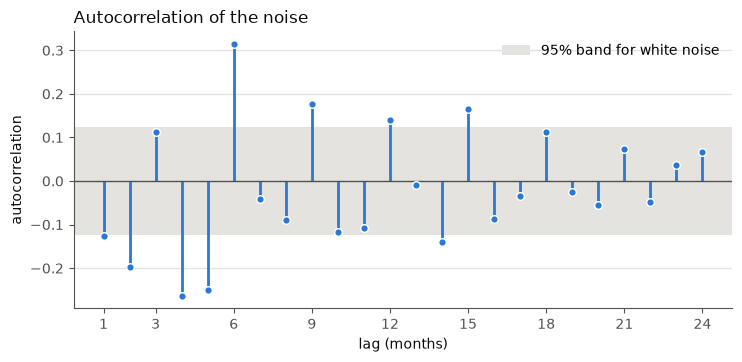

In [9]:
lags = np.arange(1, 25)
noise_acf = acf(final["noise"], nlags=24, missing="conservative")[1:]
band = 1.96 / np.sqrt(final["noise"].notna().sum())

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.axhspan(-band, band, color=GRID, lw=0, label="95% band for white noise")
ax.vlines(lags, 0, noise_acf, color=BLUE, lw=2)
ax.scatter(lags, noise_acf, s=30, color=BLUE, edgecolor="white", linewidth=1, zorder=3)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks([1, 3, 6, 9, 12, 15, 18, 21, 24])
ax.set_xlabel("lag (months)", color=INK)
ax.set_ylabel("autocorrelation", color=INK)
ax.set_title("Autocorrelation of the noise", loc="left", color=INK)
ax.legend(frameon=False, loc="upper right")
style_axes(ax)
save(fig, "noise_acf")
plt.show()

The noise is not white. It has a three-month rhythm: positive autocorrelation at lags 3, 6, 9, 12 and 15, and negative values in between, largest at lags 1–2 and 4–5. The quarterly issue pattern fades gradually, and two fixed halves can only approximate a gradual change, so part of the seasonality stays in the noise. A seasonality that changes smoothly over time would capture more of it, but that goes beyond what Prophet offers without custom terms, and the remaining structure is small next to the trend.

## 7. The topic panel

The project's topic panel holds every topic-year with at least 100 journal articles with abstracts. For a monthly analysis I use the 54 topics that are in the panel in all 24 years, so every topic has a complete series. Each topic gets the final model (January spread and missing, conditional seasonality, default trend flexibility), and the table reports, for each topic:

- **trend growth:** the trend in 2022–2024 relative to 2001–2003 (a factor);
- **standard deviations** of seasonality (in each half), cycle and noise, in log points × 100;
- **counting SD:** the noise a Poisson count with the model's expected monthly count would have, 1/√(expected count), averaged over months.

In [10]:
topic_counts = pd.read_csv(TOPIC_COUNTS)
years_in_panel = topic_counts[topic_counts["in_panel"]].groupby("topic_id")["year"].nunique()
balanced = years_in_panel.index[years_in_panel == 24]
topics = spread_jan1(add_dates(monthly[monthly["topic_id"].isin(balanced)]
                               .merge(annual[["topic_id", "year", "jan1_articles"]], on=["topic_id", "year"])))

def summarize(fitted, frame):
    """Trend growth and the size of each other component for one fitted series."""
    observed, first = fitted["y"].notna(), fitted["ds"].dt.year <= 2012
    trend = fitted.set_index("ds")["trend"]
    per_year = frame.groupby("year")["journal_articles"].sum()
    return {"articles 2001": per_year[2001], "articles 2024": per_year[2024],
            "trend growth": np.exp(trend["2022":"2024"].mean() - trend["2001":"2003"].mean()),
            "seasonal SD 2001–12": 100 * fitted.loc[observed & first, "seasonal"].std(),
            "seasonal SD 2013–24": 100 * fitted.loc[observed & ~first, "seasonal"].std(),
            "cycle SD": 100 * fitted["cycle"].std(),
            "noise SD": 100 * fitted["noise"].std(),
            "counting SD": 100 * np.sqrt(np.exp(-fitted.loc[observed, "yhat"]).mean())}

rows = [{"topic": "Whole field", **summarize(final, field)}]
for topic_id, frame in topics.groupby("topic_id"):
    frame = frame.sort_values("ds").reset_index(drop=True)
    _, fitted = fit_prophet(frame, np.log(frame["spread"]).where(frame["month"] != 1), conditional=True)
    fitted["cycle"], fitted["noise"] = cycle_and_noise(fitted)
    rows.append({"topic": frame["topic_name"].iloc[0], **summarize(fitted, frame)})
table = pd.DataFrame(rows)
table.to_csv(TABLES / "week7_topic_components.csv", index=False)

topic_rows = table.iloc[1:]
print(f"{len(topic_rows)} topics. Median trend growth {topic_rows['trend growth'].median():.1f}x "
      f"(range {topic_rows['trend growth'].min():.2f}x to {topic_rows['trend growth'].max():.1f}x); "
      f"seasonality weaker in 2013–24 for {(topic_rows['seasonal SD 2013–24'] < topic_rows['seasonal SD 2001–12']).sum()} topics; "
      f"median noise SD / counting SD {(topic_rows['noise SD'] / topic_rows['counting SD']).median():.2f}")
pd.concat([table.iloc[:1], topic_rows.sort_values("trend growth", ascending=False)]).round(
    {"trend growth": 2, "seasonal SD 2001–12": 1, "seasonal SD 2013–24": 1, "cycle SD": 1, "noise SD": 1,
     "counting SD": 1}).set_index("topic")

54 topics. Median trend growth 3.1x (range 0.87x to 11.0x); seasonality weaker in 2013–24 for 38 topics; median noise SD / counting SD 1.14


,articles 2001,articles 2024,trend growth,seasonal SD 2001–12,seasonal SD 2013–24,cycle SD,noise SD,counting SD
topic,,,,,,,,
Whole field,24810,128656,4.34,10.6,9.2,1.9,4.2,1.5
Stress and Burnout Research,159,2217,11.04,15.7,13.5,4.9,14.0,16.3
Sleep and related disorders,369,4819,10.03,10.1,13.8,6.5,17.5,10.2
Student Stress and Coping,196,2983,9.49,5.8,14.7,3.3,8.4,13.8
"LGBTQ Health, Identity, and Policy",362,3753,8.51,14.2,7.9,5.5,16.5,12.1
"Bullying, Victimization, and Aggression",267,3214,8.21,11.4,10.9,6.1,14.0,12.9
Innovative Teaching and Learning Methods,226,2624,7.97,15.2,13.2,4.8,14.0,13.6
Second Language Acquisition and Learning,240,2250,7.39,12.9,17.1,2.8,11.0,12.8
"Migration, Health and Trauma",171,1290,6.91,9.8,10.1,7.3,19.4,17.0


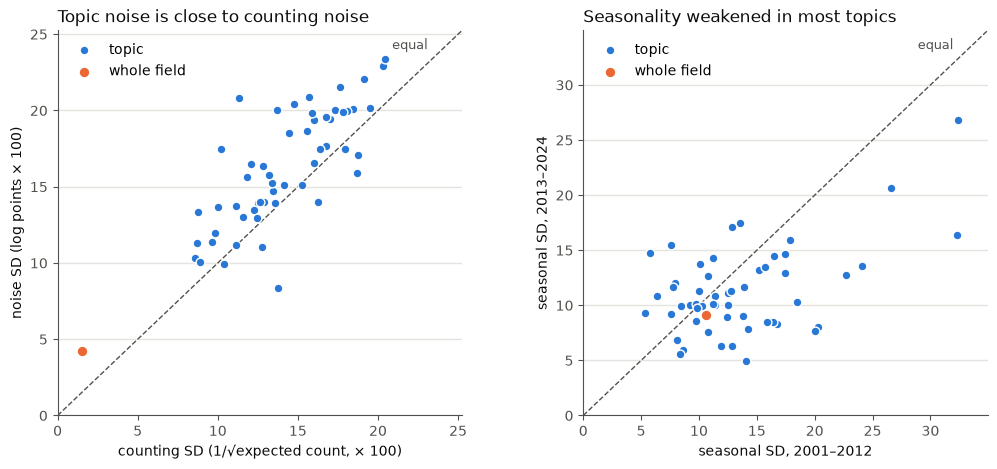

In [11]:
whole, topic_rows = table.iloc[0], table.iloc[1:]
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"wspace": 0.3})
for ax, x, y, title, xlabel, ylabel in (
        (left, "counting SD", "noise SD", "Topic noise is close to counting noise",
         "counting SD (1/√expected count, × 100)", "noise SD (log points × 100)"),
        (right, "seasonal SD 2001–12", "seasonal SD 2013–24", "Seasonality weakened in most topics",
         "seasonal SD, 2001–2012", "seasonal SD, 2013–2024")):
    top = max(table[x].max(), table[y].max()) * 1.08
    ax.plot([0, top], [0, top], color=MUTED, lw=1, ls="--")
    ax.annotate("equal", (top * 0.93, top * 0.93), xytext=(-4, 6), textcoords="offset points", ha="right",
                color=MUTED, fontsize=9)
    ax.scatter(topic_rows[x], topic_rows[y], s=40, color=BLUE, edgecolor="white", linewidth=1, label="topic", zorder=3)
    ax.scatter([whole[x]], [whole[y]], s=60, color=ORANGE, edgecolor="white", linewidth=1, label="whole field", zorder=4)
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.set_xlabel(xlabel, color=INK)
    ax.set_ylabel(ylabel, color=INK)
    ax.set_title(title, loc="left", color=INK)
    ax.legend(frameon=False, loc="upper left")
    style_axes(ax)
save(fig, "topic_components")
plt.show()

**Trend.** The 54 topics grew at very different rates: from slight decline (Psychological Testing and Assessment, 0.87×) to elevenfold (Stress and Burnout Research). The median topic grew about threefold (3.1×), less than the field as a whole (4.3×); topics that were too small for the panel in 2001 and grew later are not in this balanced set.

**Seasonality** weakened in 38 of the 54 topics, as it did, slightly, for the field (SD 10.6 to 9.2).

**Noise.** For the topics, the noise is only about 1.1 times what a pure counting process would produce, and topics with fewer papers have more noise. For the whole field the picture is reversed: its noise (4.2) is nearly three times its counting noise (1.5). A topic with 60 articles a month is noisy mainly because 60 is a small number; the field, with 5,000 a month, is noisy because of dating and issue timing.

This matters for the project's panel regression, which relates each topic's yearly change in KE to its yearly change in output, Δlog N<sub>kt</sub>. Counting noise does not disappear in yearly counts, so the next cell asks how much of the year-to-year variation in topic growth it accounts for.

In [12]:
panel = topic_counts[topic_counts["in_panel"]].sort_values(["topic_id", "year"]).copy()
panel["d_log_n"] = panel.groupby("topic_id")["journal_articles"].transform(lambda n: np.log(n).diff())
panel["previous"] = panel.groupby("topic_id")["journal_articles"].shift()
pairs = panel[panel.groupby("topic_id")["year"].diff().eq(1)].copy()   # consecutive panel years only

within = smf.ols("d_log_n ~ C(topic_id) + C(year)", data=pairs).fit()   # the panel's topic and year effects
counting = (1 / pairs["journal_articles"] + 1 / pairs["previous"]).mean()   # Poisson variance of a log change
print(f"{len(pairs):,} consecutive topic-year pairs, median {pairs['journal_articles'].median():.0f} articles a year")
print(f"Variance of yearly growth left after topic and year effects: {within.mse_resid:.5f}")
print(f"Variance that counting noise alone would produce:            {counting:.5f} "
      f"({counting / within.mse_resid:.0%} of it)")

1,974 consecutive topic-year pairs, median 520 articles a year
Variance of yearly growth left after topic and year effects: 0.01054
Variance that counting noise alone would produce:            0.00473 (45% of it)


Close to half (45%) of the year-to-year variation in topic growth that is left after topic and year effects, the variation the panel regression uses, is what counting alone would produce. If KE responds to a topic's underlying growth rather than to the exact number of papers it happened to publish in one year, this part of Δlog N<sub>kt</sub> works like measurement error in the regressor, and it would bias the estimated relationship toward zero.

## Summary

- **Trend.** Psychology's monthly output grew about fivefold between 2001 and 2024. Growth was faster in the 2000s (7–10% a year) than in the 2010s (about 5–6%), surged in 2019–2020 (11–12%), and returned to about 6%. A ten times more flexible trend tells the same story.
- **The January artefact.** OpenAlex dates a paper 1 January when only its year is known, which affects 26% of the field's 2001 articles and 8.5% of 2024's. Without a correction, Prophet reads this as a January effect of nearly +200%. Spreading these papers over their year and treating January as missing removes the artefact without changing any annual total.
- **Seasonality.** Quarterly peaks (March, June, September, December) dominated in 2001–2012; by 2013–2024 the year had one main peak in December. Seasonality also weakened in 38 of the 54 topics.
- **Cycles** are small (SD 1.9); the largest swings fall in 2019–2023, around the pandemic years.
- **Noise** (SD 4.2) is twice the size of the cycle and still carries a three-month rhythm. For individual topics it is mostly counting noise, and counting noise accounts for close to half (45%) of the year-to-year variation in topic growth that the panel regression would use.

These are descriptions of publication counts in one database. They describe when papers are dated, not when the research was done, and the seasonal pattern reflects publishing practice, not the rhythm of science.

## What I learned and next steps

**What I learned**

- **Check how the dates were recorded before reading seasonality.** The largest "seasonal" effect in the raw data, January at three times the trend, came from how OpenAlex records missing months. The baseline fit looked reasonable; only the share of papers dated exactly 1 January revealed the problem. Spreading those papers alone was not enough, because January issues carry the same date, so January had to be treated as missing. Prophet's tolerance of missing values made that step easy.
- **The components answer different questions.** The trend shows where psychology's growth rate changed. The seasonality and noise mainly describe publishing practice (issue schedules, online-first publication, date reporting). The cycle is where an event such as the pandemic-era surge appears once the trend is held to a few segments.
- **Noise depends on scale.** For a topic with 60 papers a month, most month-to-month noise is counting noise; for the whole field, it is not. The same logic applies to yearly counts, and it changes how the panel regression should be set up.

**Next steps**

1. **The regressor of the panel regression.** Close to half (45%) of the variation in yearly topic growth, after topic and year effects, is counting noise. Before estimating the panel, decide (and record in the decision log) whether to use yearly Δlog N<sub>kt</sub> as is, growth over longer windows, a smoothed growth rate such as the Prophet trend's, or a correction for measurement error.
2. **Annual counts are unaffected** by the January artefact, because spreading keeps every year's total; but any analysis below the year, for example by quarter, must handle it as here.
3. **Re-run on the final field definition.** OpenAlex reassigned topics between fields on 2026-11-23; once the KE pool is re-pulled under the new definition, this notebook should be re-run on the same counts as the KE analysis.
4. Optionally, model the gradual fading of the quarterly pattern with a seasonality that changes smoothly over time, which would remove the three-month rhythm left in the noise.